# 01 - Model 1: CNN + CTC

CNN backbone followed by a 1-D convolution head (no recurrence, no attention). Pipeline: `strip -> CNN -> 1-D conv -> CTC -> text`.

**Run order:** notebook 00 first. Run this notebook top to bottom in one session.

In [1]:
import sys, json
sys.path.insert(0, ".")            # htr_data.py and htr_torch.py sit next to this notebook
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import htr_data as D
import htr_torch as T

cfg  = T.load_cfg()                # written by notebook 00
data = T.load_data(cfg)
(cfg["out"] / "figures").mkdir(exist_ok=True)
print("device :", T.get_device())
print("pages  :", {k: len(data[k]) for k in ("train", "val", "test")}, "| classes incl. blank:", T.n_classes(data))

device : cpu
pages  : {'train': 361, 'val': 87, 'test': 90} | classes incl. blank: 156


## 1. Settings

In [2]:
HEAD   = "cnn"
EPOCHS = 60      # CPU is slow (~1-3 min per epoch). For a first quick run use EPOCHS = 20; on Colab/Kaggle GPU it is much faster.
LR     = 1e-3

## 2. Sanity check (do this once, before any real training)

The network must be able to **memorise 6 pages**. If it can, the images and labels are aligned and the whole pipeline works.
If it cannot, stop and recheck notebook 00 - training longer will not help.
(The CER printed at the start stays near 1.0 for a while: that is the normal CTC "all blank" phase.)

In [3]:
ok = T.overfit_check("bilstm", data, cfg, n_pages=6, epochs=120)


c:\Users\dasar\Downloads\Final Year Capstone Project\htr_torch.py:390: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:821.)
  print(f"overfit {head}: epoch {ep:3d} loss {float(loss):.3f}  CER on the {n_pages} training pages {c:.3f}  "


overfit bilstm: epoch   1 loss 19.424  CER on the 6 training pages 1.000  (0.5 min)
overfit bilstm: epoch  10 loss 3.413  CER on the 6 training pages 1.000  (4.8 min)
overfit bilstm: epoch  20 loss 3.381  CER on the 6 training pages 1.000  (10.0 min)
overfit bilstm: epoch  30 loss 3.379  CER on the 6 training pages 1.000  (15.3 min)
overfit bilstm: epoch  40 loss 3.378  CER on the 6 training pages 1.000  (22.5 min)
overfit bilstm: epoch  50 loss 3.376  CER on the 6 training pages 1.000  (48.8 min)
overfit bilstm: epoch  60 loss 3.376  CER on the 6 training pages 1.000  (54.4 min)
overfit bilstm: epoch  70 loss 3.375  CER on the 6 training pages 1.000  (60.1 min)
overfit bilstm: epoch  80 loss 3.373  CER on the 6 training pages 1.000  (65.6 min)
overfit bilstm: epoch  90 loss 3.370  CER on the 6 training pages 1.000  (72.2 min)
overfit bilstm: epoch 100 loss 3.369  CER on the 6 training pages 1.000  (77.7 min)
overfit bilstm: epoch 110 loss 3.338  CER on the 6 training pages 1.000  (83.

## 3. Train

Best checkpoint = lowest **validation** CER. Early in training CER = 1.0 is normal; it should start dropping within roughly 10-25 epochs.

In [4]:
out = T.train_model(HEAD, data, cfg, epochs=EPOCHS, lr=LR, tag=HEAD)
print("best validation CER:", round(out["best_val_CER"], 4), "at epoch", out["best_epoch"], f"({out['minutes']:.1f} min)")

[cnn] device=cpu params=1,428,860 train pages=361 val pages=87
[cnn] ep   1/60 | train 4.852 | val loss 3.510 | val CER 1.000 WER 1.000 | best 1.000 @ 1 | 4.0 min
[cnn] ep   2/60 | train 3.640 | val loss 3.726 | val CER 1.000 WER 1.000 | best 1.000 @ 1 | 7.9 min
[cnn] ep   3/60 | train 3.646 | val loss 3.357 | val CER 0.874 WER 1.000 | best 0.874 @ 3 | 11.6 min
[cnn] ep   4/60 | train 3.460 | val loss 3.339 | val CER 0.861 WER 1.000 | best 0.861 @ 4 | 15.4 min
[cnn] ep   5/60 | train 3.279 | val loss 3.041 | val CER 0.823 WER 0.992 | best 0.823 @ 5 | 19.2 min
[cnn] ep   6/60 | train 3.220 | val loss 3.027 | val CER 0.808 WER 1.000 | best 0.808 @ 6 | 23.0 min
[cnn] ep   7/60 | train 3.112 | val loss 3.257 | val CER 0.824 WER 0.991 | best 0.808 @ 6 | 26.8 min
[cnn] ep   8/60 | train 2.966 | val loss 2.789 | val CER 0.754 WER 0.996 | best 0.754 @ 8 | 30.8 min
[cnn] ep   9/60 | train 2.843 | val loss 2.700 | val CER 0.706 WER 1.038 | best 0.706 @ 9 | 36.9 min
[cnn] ep  10/60 | train 2.760 

## 4. Training curves

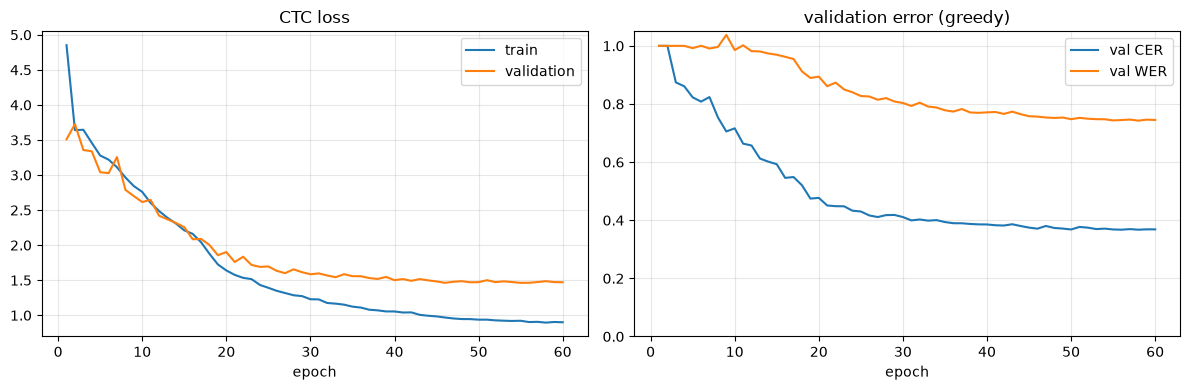

In [5]:
h = out["history"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="validation")
ax[0].set_title("CTC loss"); ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(h.epoch, h.val_CER, label="val CER"); ax[1].plot(h.epoch, h.val_WER, label="val WER")
ax[1].set_ylim(0, 1.05); ax[1].set_title("validation error (greedy)"); ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(cfg["out"] / "figures" / f"{HEAD}_training.png", dpi=150); plt.show()

## 5. Evaluate the best checkpoint on validation and test

In [8]:
model, res = T.evaluate_checkpoint(HEAD, data, cfg)
r = T.save_result(HEAD, HEAD, res, out, cfg, data)
print(pd.Series(r).to_string())

tag                   cnn
head                  cnn
params            1428860
best_epoch             58
train_minutes       427.3
val_CER          0.367475
val_WER          0.742667
test_CER         0.231334
test_WER         0.629469
train_pages           361
val_pages              87
test_pages             90


In [9]:
te = res["test"]["df"]
for lang, g in te.groupby("language"):
    print(f"{lang:8s} pages={len(g):3d}  CER={D.corpus_cer(g.reference, g.prediction):.4f}  WER={D.corpus_wer(g.reference, g.prediction):.4f}")

print()
order = te.sort_values("CER").reset_index(drop=True)
for name, i in [("BEST", 0), ("MEDIAN", len(order) // 2), ("WORST", len(order) - 1)]:
    row = order.iloc[i]
    print(f"--- {name}  ({row.id}, {row.language})  CER {row.CER:.3f}")
    print("reference :", row.reference[:200])
    print("prediction:", row.prediction[:200])

Hindi    pages= 49  CER=0.2769  WER=0.6260
Marathi  pages= 41  CER=0.1885  WER=0.6339

--- BEST  (ma_850_110803, Marathi)  CER 0.082
reference : यंत्र स्वअध्ययनाने उद्योगांमध्ये'९० च्या दशकात प्रवेश करायला सुरुवात केली माझ्या शाळेतल्या मित्रमैत्रिणींची नावंही त्यांना माहीत होती. देवाचे अटळ नियम आपल्याला दिलासा देतात. त्याअर्थी, यहोवावर असलेले 
prediction: यंत्र स्व अध्ययनाने उद्ोगांमध्ये १० च्या दशकात प्रवेश करायला सुरूवात केलीमाझ्या थाळेतल्या मित्रमैत्रिणीची नावंही त्यांना माहीत होती. देवाचे अटव्ठ नियम आपल्याला दिलासा देतात. त्याअथा, यहोवावर असनेले प्
--- MEDIAN  (ma_713_111105, Marathi)  CER 0.215
reference : ह्यामुळे सिलिगुडीचे रेल्वे जंक्शन म्हणून महत्त्व वाढीस लागले. गिफ्ट सिटी आणि भारतीय आंतरराष्ट्रीय शेअरबाजाराला मी खूप खूप शुभेच्छा देतो. २००९; पुणे, महाराष्ट्र) हे मराठी नाट्य-अभिनेते, चित्रपट अभिनेते
prediction: प२ार० दामुके सिलिमुडीचे ऐेळे जंवशन क्दणून महत्व वाढीम लागली. गिप्ट सिटी आणि भारनीय औंतरराष्रीय शेअरवाजाराला ी खूप खु शुभेच्छा देती. २००४ परणे, मदाराष्ट) हे माराठी नाठा-

**How to read the numbers.** CER = character errors / reference characters (0 = perfect, 1 = everything wrong, can exceed 1).
WER is the same on words and is always higher. With about 300 training pages and no pre-training, expect a clearly non-zero CER;
what matters for the project is the *comparison between models* (notebook 04) and that the result is honest (writer-disjoint test).